# The 2019–20 shift in garimpo

Garimpo cases, gold PLG requests and non-garimpo malaria all break around 2019–20 in
lead 1's IGD municipalities (E11). This notebook separates two candidate causes
(`output/research/mining_economics_leads.md`, E12):

- **The Roraima rush:** the totals by group, and lead 1's IGD event study split into IGD
  municipalities in Roraima (the Yanomami territory) and elsewhere, relative to 2018.
- **The enforcement collapse** (lead 3): IBAMA's fines fell from 2019 and recovered in
  2023. *Presence* is the log of a municipality's mean yearly IBAMA fines in 2010–2014,
  standardised across the Legal Amazon. On 2015–2024, presence × post-2019 and
  × post-2023, with the log BRL gold price × deposits, municipality and year FE,
  unweighted, Otto-3 clusters and the wild-cluster bootstrap.
  - The fines themselves are the first stage; garimpo cases and gold PLG requests are the
    reduced forms; non-garimpo malaria is the placebo.
  - Checks: presence from non-mining fines or from 2005–2010; state×year, IGD×year
    and gold×year FE; without Roraima; gold municipalities only.

Code: `src/analysis/garimpo_shift.py`. Tables go to `output/analysis/garimpo/shift_2019/`.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(PROJECT_ROOT))

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.analysis import garimpo_shift as G

warnings.filterwarnings("ignore", message=r".*singleton fixed effect")
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.max_rows", 400)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 240)
pd.set_option("display.float_format", lambda value: f"{value:.4g}")

OUT = PROJECT_ROOT / "output" / "analysis" / "garimpo" / "shift_2019"
OUT.mkdir(parents=True, exist_ok=True)

frame = G.build_frame()
frame.drop_duplicates("mun_id")["group"].value_counts()

group
rest                736
igd_other_states     21
rest_roraima          9
igd_roraima           6
Name: count, dtype: int64

## 1. Where the shift is

In [2]:
tables = []
for column, label in G.GROUP_COLUMNS.items():
    table = G.group_table(frame, column)
    tables.append(table.stack().rename("value").reset_index().assign(measure=label))
    print(label)
    display(table.astype("Int64"))
pd.concat(tables).to_csv(OUT / "group_totals.csv", index=False)

garimpo cases


group,igd_roraima,igd_other_states,rest_roraima,rest
year,,,,
2010,25,4490,15,9760
2011,12,2008,38,8068
2012,9,2234,27,8840
2013,20,1949,59,7772
2014,31,1325,12,3982
2015,29,1405,17,2482
2016,46,2154,16,2347
2017,55,1472,55,2774
2018,396,1106,82,2833


other malaria cases


group,igd_roraima,igd_other_states,rest_roraima,rest
year,,,,
2010,7639,30018,11376,261993
2011,5614,24212,6196,214048
2012,2044,19719,3842,197780
2013,2331,15926,2417,139010
2014,3077,14349,2592,113725
2015,3662,17827,2466,110089
2016,3780,20846,1873,92841
2017,4959,27124,6114,146631
2018,7820,28441,10047,136473


gold PLG requests


...

group,igd_roraima,igd_other_states,rest_roraima,rest
year,,,,
2010,137,638,219,7389
2011,154,799,223,6853
2012,180,699,336,5616
2013,143,611,120,5730
2014,86,841,111,5062
2015,110,530,253,6327
2016,103,608,157,6408
2017,54,613,134,6677
2018,69,456,239,4879


garimpo seizures


group,igd_roraima,igd_other_states,rest_roraima,rest
year,,,,
2010,0,3,0,5
2011,0,5,0,62
2012,2,5,1,22
2013,0,16,0,25
2014,1,13,2,47
2015,6,2,0,36
2016,19,12,0,28
2017,7,23,0,94
2018,8,16,1,40


garimpo destruction terms


group,igd_roraima,igd_other_states,rest_roraima,rest
year,,,,
2010,0,0,0,0
2011,0,0,0,0
2012,0,0,0,0
2013,0,0,0,0
2014,0,3,0,36
2015,5,2,0,7
2016,12,4,0,10
2017,5,16,0,33
2018,0,7,0,24


**Reading the results.** The case break is Roraima's, the enforcement response is late.
- Garimpo cases in Roraima's 6 IGD municipalities go from 9–55 a year in 2012–17 to 396
  (2018), 2,261 (2019) and 11,785 (2022), then 5,977 (2023) and 1,288 (2024).
- In the 21 IGD municipalities elsewhere they are 1,100–2,200 a year in 2013–19, then
  4,860 (2020) and 7,523 (2024).
- Non-garimpo malaria in Roraima's IGD municipalities rises from 2,044 (2012) to 26,897
  (2024); elsewhere it is flat.
- IBAMA fines in the other municipalities outside Roraima fall from 6,677 (2017) and
  4,879 (2018) to 2,610 (2020), and recover to 6,664 (2023). Garimpo seizures and destruction terms are rare until 2020 and
  surge from 2021, most of all in Roraima in 2023–24.


## 2. IGD in Roraima and elsewhere

IGD × year for Roraima and for the other states jointly, against the other Legal Amazon
municipalities, 2010–2024, relative to 2018, with the price × deposits control and Otto-3 SEs.

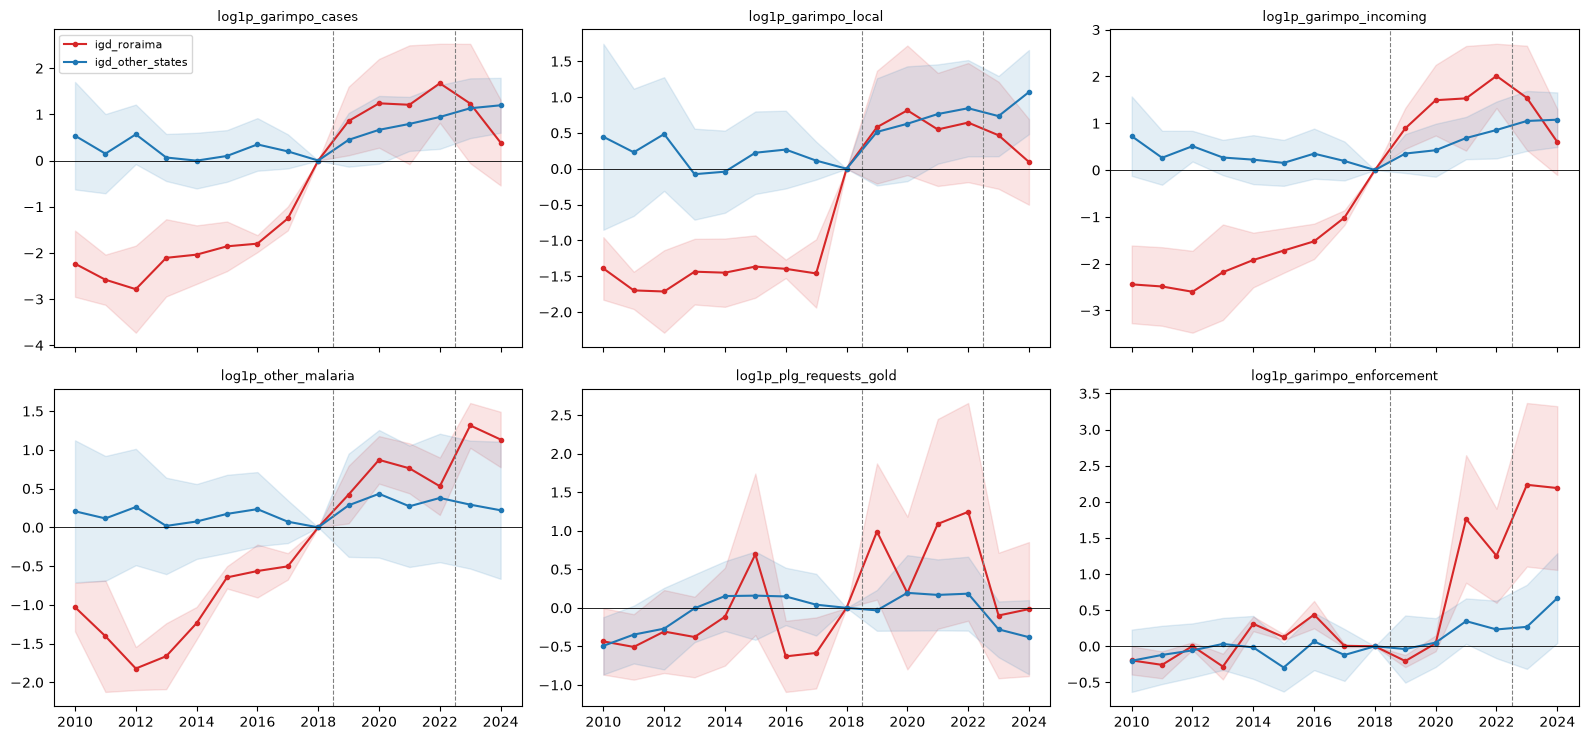

exposure    igd_other_states                                                                                                                          igd_roraima                                                                       \
outcome  log1p_garimpo_cases log1p_garimpo_enforcement log1p_garimpo_incoming log1p_garimpo_local log1p_other_malaria log1p_plg_requests_gold log1p_garimpo_cases log1p_garimpo_enforcement log1p_garimpo_incoming log1p_garimpo_local   
year                                                                                                                                                                                                                                     
2010                    0.54                      -0.2                   0.72                0.45                0.21                   -0.49               -2.23                      -0.2                  -2.44               -1.39   
2011                    0.15                     -0.12                   0.26                0.23                0.11                   -0.35               -2.58                     -0.26                  -2.49                -1.7   
2012                    0.57                     -0.06                   0.51                0.48                0.26                   -0.27               -2.79                         0                   -2.6               -1.71   
2013                    0.07                      0.03                   0.27               -0.08                0.02                   -0.01               -2.11                     -0.28                  -2.18               -1.44   
2014                      -0                     -0.02                   0.22               -0.04                0.08                    0.15               -2.04                      0.31                  -1.92               -1.45   
2015                     0.1                     -0.29                   0.15                0.22                0.17                    0.16               -1.86                      0.13                  -1.72               -1.37   
2016                    0.35                      0.07                   0.35                0.27                0.23                    0.15                -1.8                      0.44                  -1.52                -1.4   
2017                     0.2                     -0.12                   0.19                0.11                0.07                    0.04               -1.25                         0                  -1.01               -1.46   
2018                       0                         0                      0                   0                   0                       0                   0                         0                      0                   0   
2019                    0.45                     -0.04                   0.35                0.51                0.28                   -0.03                0.86                      -0.2                   0.89                0.58   
2020                    0.66                      0.05                   0.42                0.63                0.43                    0.19                1.24                      0.04                   1.49                0.81   
2021                    0.79                      0.35                   0.68                0.76                0.27                    0.17                1.21                      1.76                   1.53                0.55   
2022                    0.94                      0.23                   0.86                0.84                0.38                    0.18                1.67                      1.25                   2.01                0.64   
2023                    1.13                      0.27                   1.05                0.73                0.29                   -0.28                1.23                      2.24                   1.54                0.47   
2024                  

In [3]:
SPLIT_OUTCOMES = ["log1p_garimpo_cases", "log1p_garimpo_local", "log1p_garimpo_incoming", "log1p_other_malaria",
                  "log1p_plg_requests_gold", "log1p_garimpo_enforcement"]
split = pd.concat([G.event_study(frame, outcome, exposures=(G.IGD_RORAIMA, G.IGD_OTHER), years=(2010, 2024))
                   for outcome in SPLIT_OUTCOMES], ignore_index=True)
split.to_csv(OUT / "event_study_igd_split.csv", index=False)

fig, axes = plt.subplots(2, 3, figsize=(16, 7.5), sharex=True)
for ax, outcome in zip(axes.ravel(), SPLIT_OUTCOMES):
    for exposure, color in ((G.IGD_RORAIMA, "C3"), (G.IGD_OTHER, "C0")):
        part = split[(split.outcome == outcome) & (split.exposure == exposure)]
        ax.plot(part.year, part.estimate, marker="o", ms=3, color=color, label=exposure)
        ax.fill_between(part.year, part.estimate - 1.96 * part.se, part.estimate + 1.96 * part.se, color=color,
                        alpha=0.12)
    for year in (G.SHIFT_YEAR, G.RECOVERY_YEAR):
        ax.axvline(year - 0.5, color="grey", lw=0.8, ls="--")
    ax.axhline(0, color="black", lw=0.6)
    ax.set_title(outcome, fontsize=9)
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
plt.show()
display(split.pivot_table(index="year", columns=["exposure", "outcome"], values="estimate").round(2))

**Reading the results.** The IGD break of 2019 has two parts.
- *Roraima* (6 IGD municipalities):
  - Garimpo cases were already rising before 2019 (−2.8 in 2012, −1.25 in 2017, relative
    to 2018). They jump in 2019 (+0.86), peak in 2022 (+1.67) and fall to +0.39 in 2024,
    when garimpo enforcement there is +2.2 (2023–24).
  - Non-garimpo malaria rises steadily from 2012 (−1.8) to 2023 (+1.3), without a 2019
    break. In the Yanomami territory, cases among Indigenous people infected by the
    rush need not carry the garimpo code, so this placebo is contaminated there.
- *Other states* (21 IGD municipalities):
  - Garimpo cases are flat around zero in 2013–18 (within ±0.35) and rise steadily from
    2019 (+0.45) to 2024 (+1.20), with no reversal after 2023.
  - Non-garimpo malaria moves less (+0.27 to +0.43 in 2019–22).
  - Gold PLG requests are +0.15 to +0.19 in 2014–16 and 2020–22 and fall to −0.28 and
    −0.38 in 2023–24: the post-2023 fall in requests is outside Roraima.


## 3. Enforcement presence

group                     igd_other_states  igd_roraima  rest  rest_roraima
presence           count                21            6   736             9
                   mean               0.87         1.31 -0.04          0.62
                   std                1.27         0.61  0.97          1.24
                   min               -1.21         0.69 -1.21         -0.81
                   25%                0.09         0.82 -0.81         -0.22
                   50%                0.71          1.2 -0.22          0.16
                   75%                1.55         1.68  0.51          1.19
                   max                3.33         2.22  3.88           2.8
presence_nonmining count                21            6   736             9
                   mean               0.86         1.29 -0.04          0.62
                   std                1.27          0.6  0.97          1.25
                   min                -1.2         0.68  -1.2          -0.8
                   25%                0.09         0.82  -0.8         -0.21
                   50%                0.64         1.21 -0.27          0.13
                   75%                1.54         1.62   0.5           1.2
                   max                3.32         2.22  3.89          2.81
presence_early     count                21            6   736             9
                   mean               0.88            1 -0.04          0.49
                   std                0.87         0.47  0.99          1.11
                   min               -0.43         0.55 -1.42         -1.29
                   25%                0.33         0.66 -0.85          0.07
                   50%                0.76         0.82 -0.24          0.53
                   75%                1.41         1.33  0.65          1.48
                   max                2.69          1.7  3.29          1.82

,presence,presence_nonmining,presence_early
presence,1,0.999,0.881
presence_nonmining,0.999,1,0.881
presence_early,0.881,0.881,1


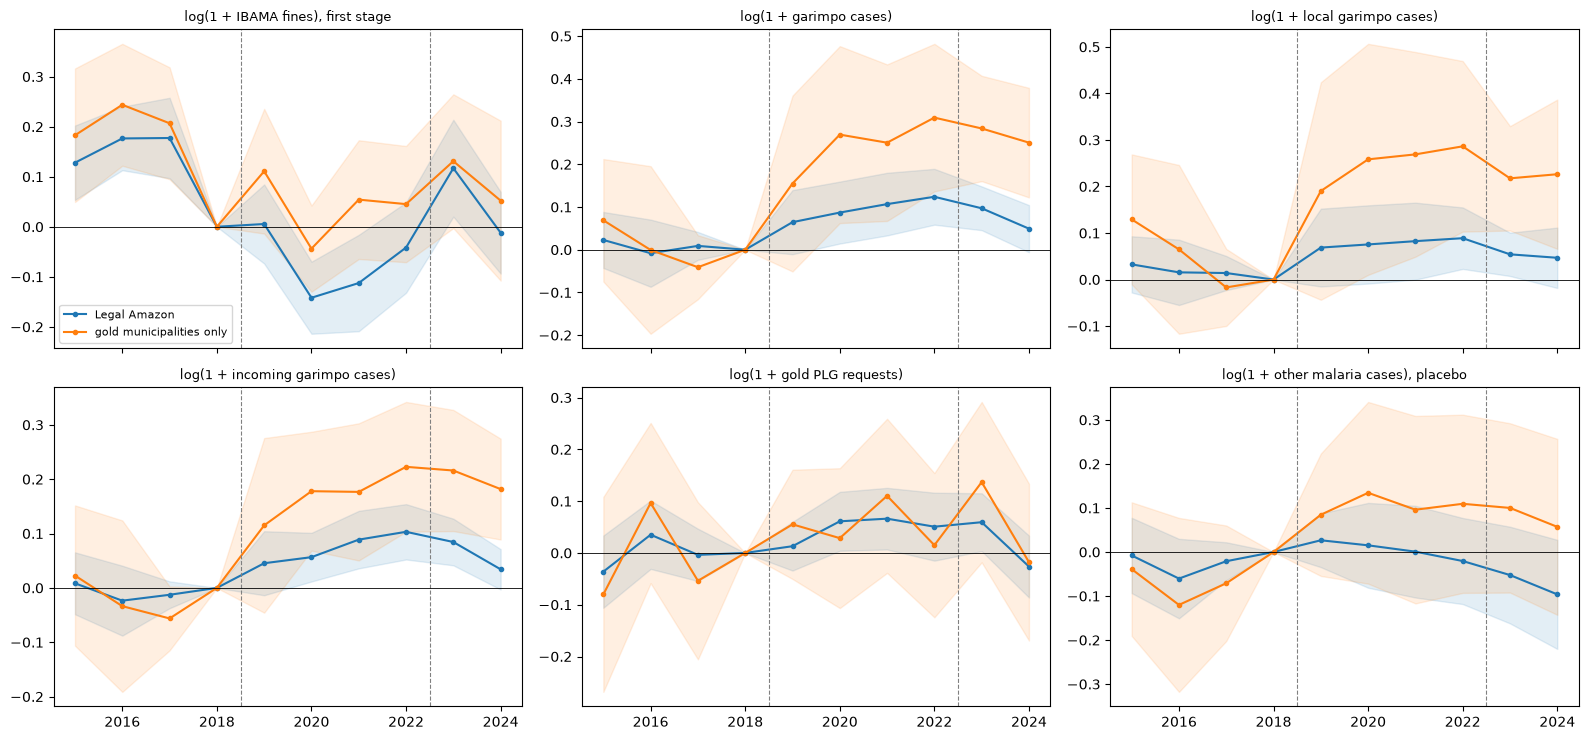

sample     Legal Amazon                                                                                                            gold municipalities only                                                                 \
outcome log1p_fines_all log1p_garimpo_cases log1p_garimpo_local log1p_garimpo_incoming log1p_plg_requests_gold log1p_other_malaria          log1p_fines_all log1p_garimpo_cases log1p_garimpo_local log1p_garimpo_incoming   
year                                                                                                                                                                                                                         
2015              0.128               0.023               0.033                  0.008                  -0.036              -0.008                    0.183               0.069               0.129                  0.023   
2016              0.177              -0.008               0.016                 -0.023                   0.035               -0.06                    0.244              -0.001               0.065                 -0.034   
2017              0.177               0.009               0.014                 -0.013                  -0.004              -0.021                    0.207              -0.041              -0.017                 -0.056   
2018                  0                   0                   0                      0                       0                   0                        0                   0                   0                      0   
2019              0.006               0.065               0.069                  0.045                   0.013               0.027                    0.111               0.155                0.19                  0.115   
2020             -0.142               0.087               0.075                  0.057                   0.061               0.015                   -0.044               0.269               0.258                  0.178   
2021             -0.112               0.107               0.083                  0.089                   0.066               0.001                    0.054               0.251               0.269                  0.177   
2022             -0.042               0.124               0.089                  0.103                   0.051               -0.02                    0.045               0.309               0.286                  0.223   
2023              0.117               0.097               0.054                  0.084                   0.059              -0.052                    0.131               0.284               0.218                  0.216   
2024             -0.012               0.049               0.047                  0.034                  -0.026              -0.096                    0.052               0.251               0.226                  0.182   

sample                                               
outcome log1p_plg_requests_gold log1p_other_malaria  
year                                                 
2015                      -0.08              -0.039  
2016                      0.096               -0.12  
2017                     -0.054              -0.071  
2018                          0                   0  
2019                      0.055               0.085  
2020                      0.029               0.134  
2021                       0.11               0.096  
2022                      0.015               0.109  
2023                      0.137                 0.1  
2024                     -0.018               0.057

In [4]:
municipalities = frame.drop_duplicates("mun_id")
display(municipalities.groupby("group")[list(G.EXPOSURES)].describe().T.round(2))
display(municipalities[list(G.EXPOSURES)].corr().round(3))

PRESENCE_OUTCOMES = list(G.OUTCOMES)
studies = pd.concat(
    [G.event_study(frame, outcome).assign(sample="Legal Amazon") for outcome in PRESENCE_OUTCOMES]
    + [G.event_study(frame, outcome, gold_only=True).assign(sample="gold municipalities only")
       for outcome in PRESENCE_OUTCOMES],
    ignore_index=True,
)
studies.to_csv(OUT / "event_study_presence.csv", index=False)
fig, axes = plt.subplots(2, 3, figsize=(16, 7.5), sharex=True)
for ax, outcome in zip(axes.ravel(), PRESENCE_OUTCOMES):
    for sample_name, color in (("Legal Amazon", "C0"), ("gold municipalities only", "C1")):
        part = studies[(studies.outcome == outcome) & (studies["sample"] == sample_name)]
        ax.plot(part.year, part.estimate, marker="o", ms=3, color=color, label=sample_name)
        ax.fill_between(part.year, part.estimate - 1.96 * part.se, part.estimate + 1.96 * part.se, color=color,
                        alpha=0.12)
    for year in (G.SHIFT_YEAR, G.RECOVERY_YEAR):
        ax.axvline(year - 0.5, color="grey", lw=0.8, ls="--")
    ax.axhline(0, color="black", lw=0.6)
    ax.set_title(G.OUTCOMES[outcome], fontsize=9)
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
plt.show()
display(studies.pivot_table(index="year", columns=["sample", "outcome"], values="estimate", sort=False).round(3))

In [5]:
table = G.run_table(frame)
table.to_csv(OUT / "presence.csv", index=False)
for term in ("post2019", "post2023"):
    part = table[table.term == term]
    print(term, "estimates (per SD of presence)")
    display(part.pivot_table(index="spec", columns="outcome", values="estimate", sort=False).round(3))
    print(term, "Otto-3 p-values")
    display(part.pivot_table(index="spec", columns="outcome", values="p_basin", sort=False).round(3))
    print(term, "wild-cluster bootstrap p-values")
    display(part.pivot_table(index="spec", columns="outcome", values="p_wcb", sort=False).round(3))
table[["spec", "n_obs", "n_municipalities", "n_basins"]].drop_duplicates("spec")

post2019 estimates (per SD of presence)


outcome,log1p_fines_all,log1p_garimpo_cases,log1p_garimpo_local,log1p_garimpo_incoming,log1p_plg_requests_gold,log1p_other_malaria
spec,,,,,,
baseline,-0.192,0.089,0.063,0.08,0.049,0.028
presence from non-mining fines,-0.192,0.087,0.061,0.078,0.048,0.025
presence 2005-2010,-0.167,0.075,0.052,0.064,0.041,0.005
state x year FE,-0.201,0.066,0.051,0.058,0.031,0.005
IGD x year FE,-0.198,0.079,0.053,0.071,0.039,0.024
gold x year FE,-0.198,0.082,0.055,0.077,0.04,0.011
without Roraima,-0.197,0.069,0.055,0.057,0.031,0.029
gold municipalities only,-0.116,0.239,0.207,0.19,0.062,0.164


post2019 Otto-3 p-values


outcome,log1p_fines_all,log1p_garimpo_cases,log1p_garimpo_local,log1p_garimpo_incoming,log1p_plg_requests_gold,log1p_other_malaria
spec,,,,,,
baseline,0,0.03,0.093,0.015,0.046,0.467
presence from non-mining fines,0,0.037,0.108,0.019,0.047,0.508
presence 2005-2010,0,0.032,0.092,0.019,0.091,0.898
state x year FE,0,0.088,0.18,0.043,0.14,0.896
IGD x year FE,0,0.022,0.096,0.007,0.065,0.505
gold x year FE,0,0.024,0.105,0.008,0.066,0.762
without Roraima,0,0.087,0.163,0.052,0.122,0.483
gold municipalities only,0.007,0.035,0.063,0.021,0.282,0.127


post2019 wild-cluster bootstrap p-values


...

post2023 Otto-3 p-values


outcome,log1p_fines_all,log1p_garimpo_cases,log1p_garimpo_local,log1p_garimpo_incoming,log1p_plg_requests_gold,log1p_other_malaria
spec,,,,,,
baseline,0,0.32,0.328,0.484,0.265,0.014
presence from non-mining fines,0,0.301,0.336,0.458,0.28,0.013
presence 2005-2010,0,0.099,0.263,0.235,0.171,0
state x year FE,0.004,0.854,0.6,0.934,0.665,0.285
IGD x year FE,0,0.229,0.309,0.321,0.576,0.016
gold x year FE,0,0.371,0.502,0.455,0.94,0.029
without Roraima,0,0.675,0.541,0.945,0.491,0.021
gold municipalities only,0.354,0.753,0.708,0.661,0.911,0.646


post2023 wild-cluster bootstrap p-values


outcome,log1p_fines_all,log1p_garimpo_cases,log1p_garimpo_local,log1p_garimpo_incoming,log1p_plg_requests_gold,log1p_other_malaria
spec,,,,,,
baseline,0,0.368,0.432,0.506,0.288,0.019
presence from non-mining fines,0,0.348,0.445,0.483,0.302,0.018
presence 2005-2010,0,0.109,0.319,0.252,0.192,0
state x year FE,0.005,0.884,0.777,0.938,0.68,0.298
IGD x year FE,0,0.265,0.4,0.34,0.593,0.019
gold x year FE,0,0.398,0.636,0.473,0.941,0.037
without Roraima,0.001,0.739,0.739,0.949,0.531,0.025
gold municipalities only,0.368,0.778,0.868,0.685,0.914,0.661


,spec,n_obs,n_municipalities,n_basins
0,baseline,7720,772,143
12,presence from non-mining fines,7720,772,143
24,presence 2005-2010,7720,772,143
36,state x year FE,7720,772,143
48,IGD x year FE,7720,772,143
60,gold x year FE,7720,772,143
72,without Roraima,7570,757,141
84,gold municipalities only,1540,154,56


**Reading the results.** Where IBAMA was present before, enforcement fell after 2019 and
garimpo cases rose; the placebo does not move.
- *First stage:* per SD of presence, fines fall 0.19 log points after 2019 and recover 0.13
  after 2023 (p < 0.001 in every spec). The event study shows the decline starting in
  2018: fines are 0.13–0.18 above 2018 in 2015–17, −0.14 in 2020 and +0.12 in 2023.
- *Garimpo cases:* +0.089 per SD after 2019 (Otto-3 p 0.03, bootstrap 0.03), flat in
  2015–17 and rising from 2019 (+0.065) to 2022 (+0.124).
  - The rise is mostly in incoming cases (+0.080, p 0.015); local cases +0.063 (p 0.09).
  - It holds with presence from non-mining fines, from 2005–2010, with IGD×year and
    gold×year FE. With state×year FE or without Roraima it is 0.07 (p 0.09).
  - Within gold municipalities it is +0.24 (p 0.035).
  - Against the first stage, a 10% fall in fines goes with about 4.6% more garimpo cases.
- *Gold PLG requests:* +0.049 (p 0.046), weaker in the checks (+0.03 to +0.06, p 0.05–0.28).
- *Placebo:* non-garimpo malaria +0.028 (p 0.47) after 2019.
- *After 2023:* fines recover, but garimpo cases (−0.022, p 0.32) and requests do not
  fall significantly. Non-garimpo malaria falls (−0.08, p 0.014), so the post-2023 term
  is not clean.
- Timing: fines in high-presence municipalities drop first from 2017 to 2018 and again
  in 2020; cases rise from 2019, the first year of the new federal government.
